# 03 - K-Means clustering

**Goal of this notebook:** group the players with K-Means for several values of `k`, and learn how to judge which values deserve a closer look.

Steps:
1. Fit one K-Means model and look at what it gives us.
2. Fit it for k = 2 to 10 and measure inertia and silhouette.
3. Check that the groups do not change when the random start changes (stability).
4. Look at players who sit between groups.
5. Save the labels of every k for the next notebooks.

**Input:** `data/processed/players_scaled.csv`
**Output:** `data/processed/cluster_labels.csv`

## 1. Imports and settings

`KMeans` is the clustering model. `silhouette_score` and `silhouette_samples` measure how well separated the groups are (one number for everybody, or one number per player). `adjusted_rand_score` compares two ways of grouping the same players.

`RANDOM_STATE` fixes the random start of K-Means so that anyone running this notebook gets the same result. `N_INIT` is how many random starts K-Means tries; it keeps the best one.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

SCALED_PATH = Path("../data/processed/players_scaled.csv")
LABELS_PATH = Path("../data/processed/cluster_labels.csv")

K_RANGE = range(2, 11)
N_INIT = 10
RANDOM_STATE = 42

META_COLUMNS = ["player_id", "player", "team", "position", "games", "minutes_per_game"]

## 2. Load

The file has the identification columns and the 9 scaled features. Only the features go into K-Means: scikit-learn models take a plain NumPy array, so we convert with `.to_numpy()`.

In [2]:
df = pd.read_csv(SCALED_PATH)
FEATURES = [col for col in df.columns if col.endswith("_per36")]
X = df[FEATURES].to_numpy()
X.shape

(325, 9)

## 3. One model, to see what we get

We ask for 5 groups. `fit(X)` runs the algorithm. Afterwards the model stores its results in attributes that end with an underscore.

In [3]:
model = KMeans(n_clusters=5, n_init=N_INIT, random_state=RANDOM_STATE).fit(X)
model.labels_[:10]  # group of the first 10 players

array([0, 0, 1, 2, 2, 2, 0, 1, 1, 2], dtype=int32)

In [4]:
pd.Series(model.labels_).value_counts().sort_index()  # players per group

0     42
1     67
2    122
3     49
4     45
Name: count, dtype: int64

`cluster_centers_` has one row per group: the "average player" of that group, in scaled units (z-scores). A positive number means the group is above the average player in that feature.

In [5]:
pd.DataFrame(model.cluster_centers_, columns=FEATURES).round(2)

,fg2a_per36,fg3a_per36,fta_per36,orb_per36,drb_per36,ast_per36,stl_per36,blk_per36,tov_per36
0,1.48,-0.35,1.59,-0.01,0.70,0.61,-0.12,-0.03,0.96
1,0.37,0.47,0.34,-0.66,-0.54,1.19,0.14,-0.50,1.05
2,-0.60,0.41,-0.51,-0.36,-0.32,-0.49,-0.49,-0.27,-0.58
3,-0.62,-0.07,-0.63,0.03,-0.26,-0.29,1.53,-0.12,-0.45
4,0.36,-1.41,0.07,1.92,1.28,-0.71,-0.45,1.62,-0.40


In [6]:
model.inertia_

1484.4494075701832

## 4. Inertia and silhouette for k = 2 to 10

- **Inertia**: sum of squared distances from every player to the center of its group. It always goes down when k grows, so we look for the *elbow*, where adding groups stops paying off.
- **Silhouette**: average over all players of `(b - a) / max(a, b)`, where `a` is the average distance to the players of the own group and `b` to the players of the nearest other group. From -1 to 1, higher is better.

In [7]:
models = {}
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(X)
    models[k] = km
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_),
    })

results = pd.DataFrame(rows).set_index("k")
results["inertia_drop"] = -results["inertia"].diff()
results.round(3)

,inertia,silhouette,inertia_drop
k,,,
2,2286.337,0.278,NaN
3,1767.670,0.251,518.667
4,1613.571,0.188,154.099
5,1484.449,0.178,129.122
6,1368.400,0.167,116.050
7,1297.168,0.157,71.232
8,1232.134,0.159,65.034
9,1189.935,0.146,42.199
10,1139.074,0.145,50.861


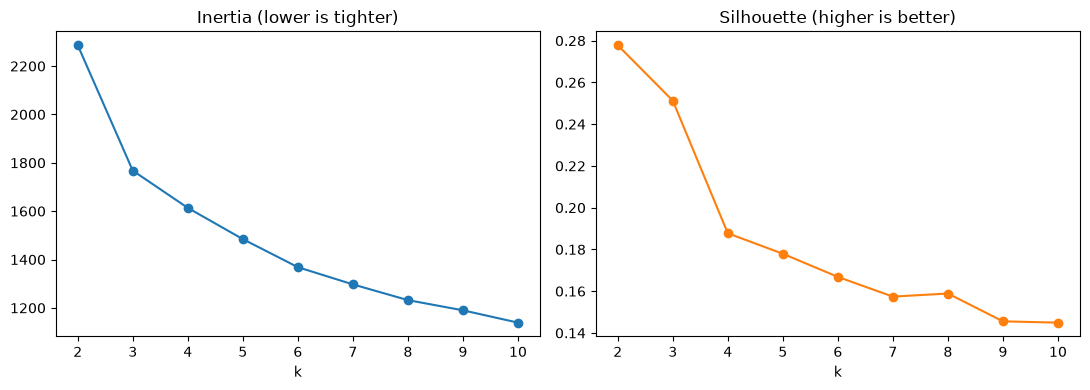

In [8]:
fig, (ax_inertia, ax_silhouette) = plt.subplots(1, 2, figsize=(11, 4))

ax_inertia.plot(results.index, results["inertia"], marker="o")
ax_inertia.set_title("Inertia (lower is tighter)")
ax_inertia.set_xlabel("k")

ax_silhouette.plot(results.index, results["silhouette"], marker="o", color="tab:orange")
ax_silhouette.set_title("Silhouette (higher is better)")
ax_silhouette.set_xlabel("k")

fig.tight_layout()

### How to read this

- **Inertia** has no sharp elbow. It falls fast from k=2 to k=3 and then keeps falling gently. A smooth curve like this is a hint that the players do not form clearly separated blocks.
- **Silhouette** is highest at k=2 (about 0.28) and below 0.2 from k=4 on. As a rule of thumb, values under roughly 0.25 mean weak structure: groups exist, but their borders are blurry. Silhouette also tends to favor small k when the data is a continuum.

This is a finding, not a failure: players seem to lie on a **spectrum** of styles more than in separate boxes. We will not choose k by silhouette alone.

## 5. Stability: do we get the same groups with another random start?

K-Means starts from random centers. If a different start gives different groups, those groups are not a reliable finding. We refit with 10 other random seeds and compare each result with our main one using the **adjusted Rand index**: 1 means identical groups, around 0 means the agreement is no better than chance.

In [9]:
def stability(k, seeds=range(1, 11)):
    reference = models[k].labels_
    scores = []
    for seed in seeds:
        other = KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit(X)
        scores.append(adjusted_rand_score(reference, other.labels_))
    return pd.Series({"mean_ari": np.mean(scores), "min_ari": np.min(scores)})


stability_table = pd.DataFrame({k: stability(k) for k in range(2, 9)}).T
stability_table.round(2)

,mean_ari,min_ari
2,0.97,0.92
3,1.00,1.00
4,0.89,0.67
5,0.70,0.45
6,0.79,0.66
7,0.55,0.49
8,0.70,0.57


Groups for k=3 are essentially the same on every start. Around k=5 the result depends clearly on the seed: there are several almost equally good ways to split the players in 5, so one particular 5-group solution is not a solid conclusion by itself.

## 6. Players between groups

K-Means puts every player in exactly one group, even a hybrid. Two tools show who is in between:

- `silhouette_samples`: the silhouette of each player. Near 0 means on the border, negative means that on average the player is closer to the members of another group.
- `model.transform(X)`: the distance from each player to **every** group center, not just the nearest one.

(A player can be assigned to the group whose *center* is nearest and still have a negative silhouette, because the silhouette uses the average distance to *all members*, and groups are not perfect spheres.)

In [10]:
K_INSPECT = 5
model = models[K_INSPECT]

df_inspect = df[META_COLUMNS].copy()
df_inspect["cluster"] = model.labels_
df_inspect["silhouette"] = silhouette_samples(X, model.labels_)

(df_inspect["silhouette"] < 0).sum()

np.int64(18)

In [11]:
df_inspect.sort_values("silhouette").head(10)[["player", "position", "cluster", "silhouette"]].round(2)

,player,position,cluster,silhouette
136,Dominick Barlow,PF,4,-0.08
110,Nikola Vučević,C,4,-0.08
55,Naji Marshall,SF,0,-0.06
238,Bones Hyland,PG,1,-0.06
237,GG Jackson II,PF,0,-0.05
111,Oso Ighodaro,PF,4,-0.04
128,Jay Huff,C,4,-0.03
135,Jerami Grant,PF,1,-0.03
61,Jaime Jaquez Jr.,SF,0,-0.03
248,Caris LeVert,SG,1,-0.02


In [12]:
distances = pd.DataFrame(
    model.transform(X),
    columns=[f"dist_to_{i}" for i in range(K_INSPECT)],
)
distances.insert(0, "player", df["player"])
distances.insert(1, "cluster", model.labels_)
distances[distances["player"].isin(["Nikola Jokić", "Luka Dončić"])].round(2)

,player,cluster,dist_to_0,dist_to_1,dist_to_2,dist_to_3,dist_to_4
36,Luka Dončić,0,4.00,4.42,6.55,6.51,7.36
42,Nikola Jokić,0,4.27,5.41,7.25,7.00,6.34


Read each row: the assigned cluster is the one with the smallest distance. When the two smallest distances are close, the player is a hybrid.

## 7. Save

We save the group of every player for **every k** (columns `kmeans_k2` ... `kmeans_k10`), so the next notebooks can use any of them without refitting.

In [13]:
df_labels = df[META_COLUMNS].copy()
for k, km in models.items():
    df_labels[f"kmeans_k{k}"] = km.labels_

df_labels.to_csv(LABELS_PATH, index=False)
df_labels.shape

(325, 15)

## Summary

- Fitted K-Means for k = 2 to 10 on the 325 players and 9 scaled features.
- Inertia has no clear elbow and silhouette is low (at most about 0.28): the styles form a spectrum with blurry borders.
- The 3-group solution is perfectly stable; the 5-group one changes with the random start.
- Hybrid players exist and K-Means cannot say so by itself; distances to every center and per-player silhouette do.
- Next: PCA, to draw the players in 2 dimensions and see which statistics drive the differences. Then we describe the groups and compare them with the five positions.